# 04a. Test Results

**Owner:** Member B
**Step 11 (joint), part 1:** score both tuned models and the four baselines on the sealed test years, 2023 to 2025, once. Part 2, `04b_comparison_analysis.ipynb` (Member A), explains the differences using the predictions saved here.

**What is fixed before this notebook runs**

- The inputs: `make_selected_preprocessor()`, agreed in step 8.
- Each model's hyperparameters and decision threshold, read from `rf_final_settings.json` and `lr_final_settings.json` (step 10).
- The group decision of 15 October: before scoring the test years, both models are refitted on **all years before them, 2007 to 2022**, with those settings and thresholds unchanged. This is how the models would be used in practice: trained on every year of history available.

**How the test years are protected.** The switch `EVALUATE_ON` below was first set to `"val"`. In that dry run the validation years 2021 to 2022 stood in for the test years and training stopped at 2020, so the notebook had to reproduce the validation results of step 10 exactly (Random Forest 0.538, Logistic Regression 0.585). Only after that check passed was it set to `"test"` and run once. Nothing about the models was changed after seeing the test results.

In [1]:
import json
import sys
import time
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve
from sklearn.pipeline import Pipeline

from src import config, viz
from src.evaluation import METRIC_NAMES, classification_metrics
from src.preprocessing import MODEL_FEATURES, build_model_frame, make_selected_preprocessor, selected_inputs

viz.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
EVALUATE_ON = "test"  # "val" was used only for the dry run; "test" is the single real run
TRAIN_SPLITS = {"test": ["train", "val"], "val": ["train"]}[EVALUATE_ON]

frame = build_model_frame()
fit_frame = frame[frame["split"].isin(TRAIN_SPLITS)].reset_index(drop=True)
eval_frame = frame[frame["split"] == EVALUATE_ON].reset_index(drop=True)
X_fit, y_fit = fit_frame[MODEL_FEATURES], fit_frame["target"]
X_eval, y_eval = eval_frame[MODEL_FEATURES], eval_frame["target"]

print(f"Evaluating on: {EVALUATE_ON} years {eval_frame['year'].min()}-{eval_frame['year'].max()}")
print(f"Training on: years {fit_frame['year'].min()}-{fit_frame['year'].max()} ({len(fit_frame):,} weeks)")
overview = eval_frame.groupby("year")["target"].agg(weeks="size", outbreak_weeks="sum", outbreak_rate="mean")
overview.loc["all"] = [len(eval_frame), int(y_eval.sum()), y_eval.mean()]
overview = overview.astype({"weeks": int, "outbreak_weeks": int})
overview

Evaluating on: test years 2023-2025
Training on: years 2007-2022 (20,775 weeks)


,weeks,outbreak_weeks,outbreak_rate
year,,,
2023,1275,230,0.180
2024,1300,97,0.075
2025,1250,40,0.032
all,3825,367,0.096


## 1. The final models

Both models are rebuilt from the settings saved in step 10. The only difference from step 10 is the training data. Because the L1 selection step is part of each pipeline, it is refitted on the same years and may keep a slightly different set of inputs; the inputs actually used are recorded below.

In [3]:
with open(config.METRICS_DIR / "rf_final_settings.json") as f:
    rf_settings = json.load(f)
with open(config.METRICS_DIR / "lr_final_settings.json") as f:
    lr_settings = json.load(f)

rf_params = dict(rf_settings["hyperparameters"], n_jobs=-1)
lr_params = {k: v for k, v in lr_settings["hyperparameters"].items() if k != "penalty"}  # L2 is the default

MODELS = {
    "Random Forest": (RandomForestClassifier(**rf_params), rf_settings["decision_threshold"]),
    "Logistic Regression": (LogisticRegression(**lr_params), lr_settings["decision_threshold"]),
}

fitted, fit_seconds, inputs_used = {}, {}, {}
for name, (estimator, threshold) in MODELS.items():
    pipeline = Pipeline([("prep", make_selected_preprocessor()), ("clf", estimator)])
    start = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    fit_seconds[name] = time.perf_counter() - start
    fitted[name] = pipeline
    inputs_used[name] = selected_inputs(pipeline)
    print(f"{name}: threshold {threshold:.3f}, fitted in {fit_seconds[name]:.1f} s, "
          f"{len(inputs_used[name])} inputs: {', '.join(inputs_used[name])}")

Random Forest: threshold 0.323, fitted in 1.6 s, 10 inputs: cases_now, cases_lag1, cases_lag2, cases_rel_threshold, rain_recent4, rain_w5_8, cases_trend, humidity_w5_8, temp_max_anom4, log_density
Logistic Regression: threshold 0.242, fitted in 0.1 s, 10 inputs: cases_now, cases_lag1, cases_lag2, cases_rel_threshold, rain_recent4, rain_w5_8, cases_trend, humidity_w5_8, temp_max_anom4, log_density


## 2. Scores for every model and baseline

The baselines are the four rules from `03_baselines.ipynb`, defined the same way. The two guessing rules learn the outbreak rate from the same training years as the models.

In [4]:
def dummy_scores(strategy):
    model = DummyClassifier(strategy=strategy, random_state=config.RANDOM_SEED).fit(X_fit[["cases_now"]], y_fit)
    return model.predict_proba(X_eval[["cases_now"]])[:, 1]

# name: (scores on the evaluation years, decision threshold)
SCORES = {
    "Random Forest": (fitted["Random Forest"].predict_proba(X_eval)[:, 1], MODELS["Random Forest"][1]),
    "Logistic Regression": (fitted["Logistic Regression"].predict_proba(X_eval)[:, 1], MODELS["Logistic Regression"][1]),
    "Persistence score": (eval_frame["cases_rel_threshold"].to_numpy(), 1.0),
    "Persistence": (eval_frame["outbreak_now"].to_numpy(), 0.5),
    "Random guessing": (dummy_scores("stratified"), 0.5),
    "Always no outbreak": (dummy_scores("most_frequent"), 0.5),
}

results = pd.DataFrame({name: classification_metrics(y_eval, s, t) for name, (s, t) in SCORES.items()}).T[METRIC_NAMES]
results[["TP", "FP", "FN", "TN"]] = results[["TP", "FP", "FN", "TN"]].astype(int)
results.index.name = f"{EVALUATE_ON} years"
results

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy,TP,FP,FN,TN
test years,,,,,,,,,,,
Random Forest,0.603,0.885,0.532,0.638,0.580,0.534,0.911,234,206,133,3252
Logistic Regression,0.595,0.884,0.524,0.662,0.585,0.540,0.910,243,221,124,3237
Persistence score,0.576,0.871,0.563,0.569,0.566,0.520,0.916,209,162,158,3296
Persistence,0.362,0.761,0.563,0.569,0.566,0.520,0.916,209,162,158,3296
Random guessing,0.098,0.511,0.122,0.095,0.107,0.025,0.847,35,253,332,3205
Always no outbreak,0.096,0.500,0.000,0.000,0.000,0.000,0.904,0,0,367,3458


**Finding.** Both tuned models beat every baseline on the ranking metrics. The Random Forest reaches PR-AUC 0.603 and Logistic Regression 0.595, against 0.576 for the persistence score and 0.096 for random guessing.

At their thresholds both catch more outbreaks than persistence: 234 and 243 of the 367 outbreak weeks, against 209. The price is more false alarms (206 and 221, against 162), so precision falls slightly (0.532 and 0.524, against 0.563), while F1 and MCC rise (F1 0.580 and 0.585, against 0.566; MCC 0.534 and 0.540, against 0.520).

The two models are almost level. The forest ranks slightly better (PR-AUC 0.603 against 0.595, ROC-AUC 0.885 against 0.884), while Logistic Regression catches nine more outbreaks at its threshold and has marginally higher F1 and MCC. Part 2 tests whether these gaps are larger than chance variation.

Accuracy misleads once more. Persistence has the highest accuracy (0.916) because it raises the fewest alarms, and always predicting no outbreak still scores 0.904.

Refitted on 2007 to 2022, the L1 selection step kept one more input than in step 10, `cases_lag2` (cases two weeks earlier), for both models (section 1).

## 3. Confusion matrices

Each model at its own decision threshold, next to persistence. The counts are weeks. The colour shows the share of each actual class, so the bottom-right cell is recall and the top-right cell is the false-alarm rate.

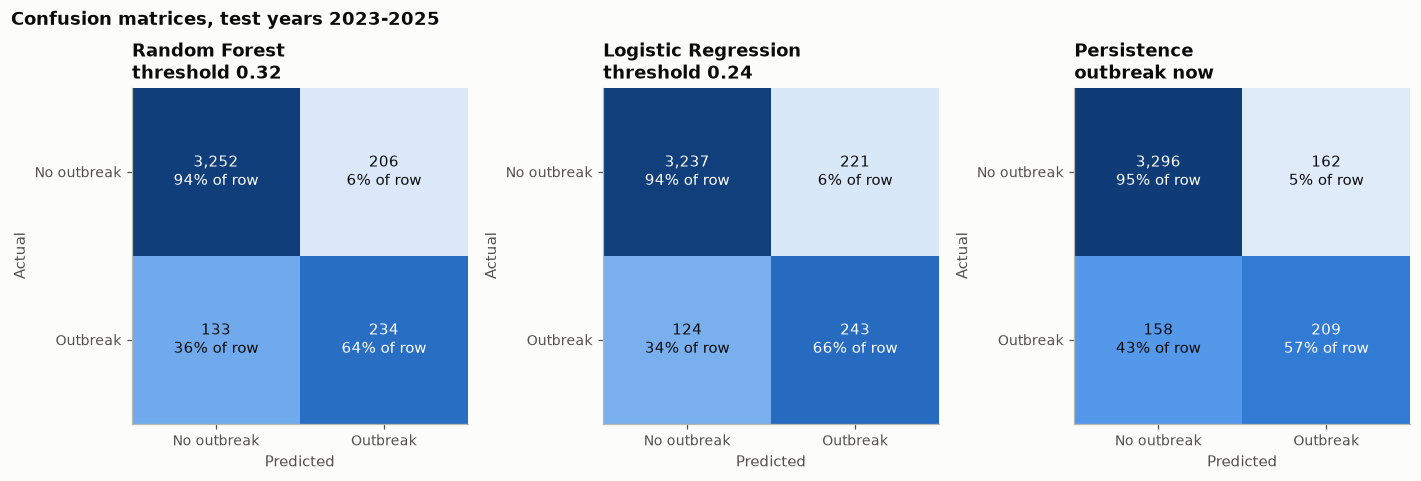

In [5]:
PANELS = ["Random Forest", "Logistic Regression", "Persistence"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, name in zip(axes, PANELS):
    r = results.loc[name]
    counts = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]], dtype=int)
    shares = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(shares, cmap=viz.SEQUENTIAL, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{counts[i, j]:,}\n{shares[i, j]:.0%} of row", ha="center", va="center", fontsize=10,
                    color="white" if shares[i, j] > 0.55 else viz.TEXT)
    ax.set_xticks([0, 1], ["No outbreak", "Outbreak"])
    ax.set_yticks([0, 1], ["No outbreak", "Outbreak"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    threshold = SCORES[name][1]
    ax.set_title(f"{name}\nthreshold {threshold:.2f}" if name != "Persistence" else f"{name}\noutbreak now")
    ax.grid(False)
fig.suptitle(f"Confusion matrices, {EVALUATE_ON} years {eval_frame['year'].min()}-{eval_frame['year'].max()}",
             x=0.01, ha="left", fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "test_01_confusion_matrices")
plt.show()

**Finding.** Along the bottom rows, the forest catches 64% of outbreak weeks, Logistic Regression 66% and persistence 57%. Along the top rows, each raises a false alarm in 5 to 6% of the weeks without an outbreak. Both models sit on the same trade-off as persistence, catching more outbreaks for a few more false alarms. Neither brings the missed outbreaks much below a third: 133 and 124 outbreak weeks still pass without a warning.

## 4. Precision-recall and ROC curves

The curves show every possible threshold, not only the chosen one. The marker on each model's curve is its chosen operating point; persistence is a single point because it only says yes or no. On the precision-recall chart the dashed line is the outbreak rate, the precision of random guessing.

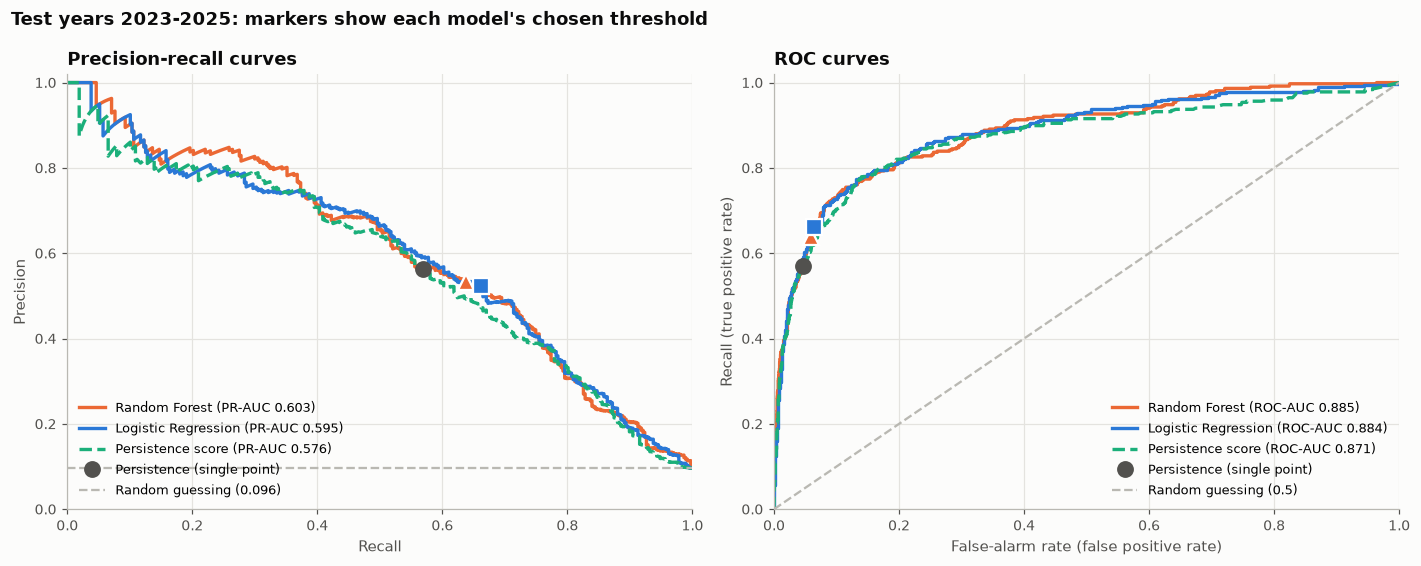

In [6]:
CURVES = [("Random Forest", viz.ORANGE, "-", "^"), ("Logistic Regression", viz.BLUE, "-", "s"),
          ("Persistence score", viz.AQUA, "--", "D")]
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(13, 5.2))

for name, colour, style, marker in CURVES:
    scores, threshold = SCORES[name]
    precision, recall, _ = precision_recall_curve(y_eval, scores)
    ax_pr.plot(recall, precision, color=colour, linestyle=style, linewidth=2.2,
               label=f"{name} (PR-AUC {results.loc[name, 'PR-AUC']:.3f})")
    fpr, tpr, _ = roc_curve(y_eval, scores)
    ax_roc.plot(fpr, tpr, color=colour, linestyle=style, linewidth=2.2,
                label=f"{name} (ROC-AUC {results.loc[name, 'ROC-AUC']:.3f})")
    if name != "Persistence score":
        r = results.loc[name]
        ax_pr.plot(r["recall"], r["precision"], marker=marker, color=colour, markersize=11,
                   markeredgecolor="white", markeredgewidth=1.5, zorder=5)
        ax_roc.plot(r["FP"] / (r["FP"] + r["TN"]), r["recall"], marker=marker, color=colour, markersize=11,
                    markeredgecolor="white", markeredgewidth=1.5, zorder=5)

r = results.loc["Persistence"]
ax_pr.plot(r["recall"], r["precision"], "o", color=viz.TEXT_MUTED, markersize=10, zorder=5, label="Persistence (single point)")
ax_roc.plot(r["FP"] / (r["FP"] + r["TN"]), r["recall"], "o", color=viz.TEXT_MUTED, markersize=10, zorder=5,
            label="Persistence (single point)")
ax_pr.axhline(y_eval.mean(), color=viz.NEUTRAL, linestyle="--", linewidth=1.5,
              label=f"Random guessing ({y_eval.mean():.3f})")
ax_roc.plot([0, 1], [0, 1], color=viz.NEUTRAL, linestyle="--", linewidth=1.5, label="Random guessing (0.5)")

ax_pr.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall", ylabel="Precision", title="Precision-recall curves")
ax_roc.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False-alarm rate (false positive rate)",
           ylabel="Recall (true positive rate)", title="ROC curves")
ax_pr.legend(loc="lower left", fontsize=8.5)
ax_roc.legend(loc="lower right", fontsize=8.5)
fig.suptitle(f"{EVALUATE_ON.capitalize()} years {eval_frame['year'].min()}-{eval_frame['year'].max()}: "
             "markers show each model's chosen threshold", x=0.01, ha="left", fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "test_02_pr_roc_curves")
plt.show()

**Finding.** The three ranking curves lie close together, so the models' gains are real but modest. Between recall 0.6 and 0.75, the region where the chosen thresholds sit, both model curves run above the persistence score by a few points of precision. The forest's curve is the highest around recall 0.2 to 0.3, its most confident warnings, while near recall 0.8 the persistence score is level or slightly ahead. Both operating points lie to the right of persistence on the precision-recall chart: more outbreaks caught for slightly lower precision. On the ROC chart the three curves almost coincide (ROC-AUC 0.871 to 0.885).

## 5. Year by year

The three years differ in how many outbreaks they hold, so each is scored separately. As before, PR-AUC can only be compared within a year, because its floor (the outbreak rate) changes from year to year.

In [7]:
rows = []
for year, part in eval_frame.groupby("year"):
    idx = part.index.to_numpy()
    for name in ["Random Forest", "Logistic Regression", "Persistence score", "Persistence"]:
        scores, threshold = SCORES[name]
        m = classification_metrics(y_eval.iloc[idx], scores[idx], threshold)
        rows.append({"year": year, "model": name, "outbreak rate": y_eval.iloc[idx].mean(),
                     **{k: m[k] for k in ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", "MCC", "TP", "FP", "FN"]}})
by_year = pd.DataFrame(rows)
by_year.pivot_table(index="model", columns="year", values=["PR-AUC", "recall", "precision", "F1"], sort=False).round(3)

PR-AUC             recall             precision                F1            
year                  2023  2024  2025   2023  2024  2025      2023  2024  2025  2023  2024  2025
model                                                                                            
Random Forest        0.625 0.665 0.385  0.648 0.701 0.425     0.580 0.557 0.279 0.612 0.621 0.337
Logistic Regression  0.592 0.726 0.374  0.626 0.835 0.450     0.581 0.562 0.250 0.603 0.672 0.321
Persistence score    0.584 0.682 0.365  0.548 0.711 0.350     0.606 0.556 0.359 0.575 0.624 0.354
Persistence          0.413 0.417 0.146  0.548 0.711 0.350     0.606 0.556 0.359 0.575 0.624 0.354

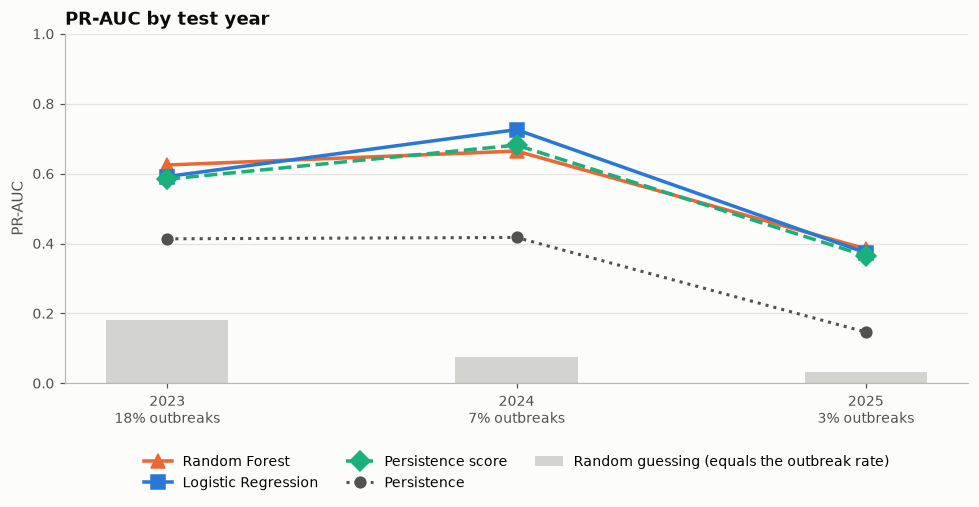

In [8]:
years = sorted(eval_frame["year"].unique())
x = np.arange(len(years))
pr = by_year.pivot_table(index="model", columns="year", values="PR-AUC", sort=False)
rates = by_year.groupby("year")["outbreak rate"].first().to_numpy()

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x, rates, width=0.35, color=viz.NEUTRAL, alpha=0.6, zorder=1, label="Random guessing (equals the outbreak rate)")
for name, colour, style, marker in CURVES:
    ax.plot(x, pr.loc[name, years], color=colour, linestyle=style, linewidth=2.3, marker=marker, markersize=9,
            label=name, zorder=3)
ax.plot(x, pr.loc["Persistence", years], color=viz.TEXT_MUTED, linestyle=":", linewidth=2, marker="o",
        markersize=7, label="Persistence", zorder=2)
ax.set_xticks(x, [f"{y}\n{r:.0%} outbreaks" for y, r in zip(years, rates)])
ax.set_ylim(0, 1)
ax.set_ylabel("PR-AUC")
ax.set_title(f"PR-AUC by {EVALUATE_ON} year")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "test_03_by_year")
plt.show()

**Finding.** No model leads in every year, which matches the mixed picture from cross-validation and the validation years.

- **2023, the busiest test year (18% outbreak weeks):** the forest leads, with PR-AUC 0.625 against 0.592 for Logistic Regression and 0.584 for the persistence score.
- **2024 (7%):** Logistic Regression leads clearly (0.726 against 0.682 for the persistence score) and catches 84% of outbreak weeks; the forest falls just below the persistence score (0.665).
- **2025, the quietest year with only 40 outbreak weeks:** all three are within about 0.02 of each other (forest 0.385, Logistic Regression 0.374, persistence score 0.365).

## 6. Summary

- **Test set:** 2023 to 2025, 3,825 district-weeks, 367 of them outbreak weeks (9.6%). Both models were trained on 2007 to 2022 with the settings and thresholds fixed in step 10, and scored once.
- **PR-AUC:** Random Forest 0.603, Logistic Regression 0.595, persistence score 0.576, persistence 0.362, random guessing 0.096.
- **At the chosen thresholds:** the forest catches 234 of 367 outbreak weeks (64%), Logistic Regression 243 (66%) and persistence 209 (57%), with 206, 221 and 162 false alarms. F1: 0.580, 0.585 and 0.566. MCC: 0.534, 0.540 and 0.520.
- **Both models beat the strongest baseline** on every metric except precision and accuracy, both of which favour raising fewer alarms.
- **The two models are nearly level:** the forest ranks slightly better, Logistic Regression catches slightly more outbreaks, and the lead changes from year to year.

Part 2, `04b_comparison_analysis.ipynb`, tests whether these differences exceed chance and explains them through how each algorithm works.

## 7. Saved for part 2

`04b_comparison_analysis.ipynb` works only from the files saved here, so the models are not refitted and the test years are not scored again.

In [9]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
prefix = "test" if EVALUATE_ON == "test" else "dryrun_val"

predictions = eval_frame[[config.DISTRICT_COL, config.DATE_COL, "year", "week", "target", "outbreak_now",
                          "cases_rel_threshold"]].copy()
for name, key in [("Random Forest", "rf"), ("Logistic Regression", "lr")]:
    scores, threshold = SCORES[name]
    predictions[f"{key}_score"] = scores
    predictions[f"{key}_warning"] = (scores >= threshold).astype(int)
predictions.to_csv(config.METRICS_DIR / f"{prefix}_predictions.csv", index=False)
results.to_csv(config.METRICS_DIR / f"{prefix}_metrics.csv")
by_year.to_csv(config.METRICS_DIR / f"{prefix}_metrics_by_year.csv", index=False)

final_models = {
    "evaluated_on": f"{EVALUATE_ON} years {eval_frame['year'].min()}-{eval_frame['year'].max()}",
    "trained_on": f"years {fit_frame['year'].min()}-{fit_frame['year'].max()} ({len(fit_frame)} weeks)",
    "models": {
        name: {"hyperparameters": (rf_params if name == "Random Forest" else lr_params),
               "decision_threshold": MODELS[name][1],
               "inputs_used": inputs_used[name],
               "fit_seconds": round(fit_seconds[name], 2)}
        for name in MODELS
    },
}
with open(config.METRICS_DIR / f"{prefix}_final_models.json", "w") as f:
    json.dump(final_models, f, indent=2, default=str)
print(f"Saved {prefix}_predictions.csv, {prefix}_metrics.csv, {prefix}_metrics_by_year.csv "
      f"and {prefix}_final_models.json to results/metrics/")

Saved test_predictions.csv, test_metrics.csv, test_metrics_by_year.csv and test_final_models.json to results/metrics/
